In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.base import clone
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler, QuantileTransformer
from sklearn.model_selection import (
    GroupShuffleSplit,
    GroupKFold,
    cross_validate,
    GridSearchCV,
)
from sklearn.metrics import root_mean_squared_error, mean_absolute_error



red = pd.read_csv("data/winequality-red.csv", sep=";")
white = pd.read_csv("data/winequality-white.csv", sep=";")

red = red.assign(is_red=1)
white = white.assign(is_red=0)
df = pd.concat([red, white], ignore_index=True)

print(df.shape)
print(df.head())

(6497, 13)
   fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
0            7.4              0.70         0.00             1.9      0.076   
1            7.8              0.88         0.00             2.6      0.098   
2            7.8              0.76         0.04             2.3      0.092   
3           11.2              0.28         0.56             1.9      0.075   
4            7.4              0.70         0.00             1.9      0.076   

   free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
0                 11.0                  34.0   0.9978  3.51       0.56   
1                 25.0                  67.0   0.9968  3.20       0.68   
2                 15.0                  54.0   0.9970  3.26       0.65   
3                 17.0                  60.0   0.9980  3.16       0.58   
4                 11.0                  34.0   0.9978  3.51       0.56   

   alcohol  quality  is_red  
0      9.4        5       1  
1      9.8     

In [2]:
#первичная обработка данных
print('пропуски')
print(df.isna().sum(),'\n')

print('дубликаты')
print(df.duplicated().sum())

пропуски
fixed acidity           0
volatile acidity        0
citric acid             0
residual sugar          0
chlorides               0
free sulfur dioxide     0
total sulfur dioxide    0
density                 0
pH                      0
sulphates               0
alcohol                 0
quality                 0
is_red                  0
dtype: int64 

дубликаты
1177


разделяю обучающую и тестовую выборку 80 на 20

In [3]:
# разделение обучающих данных
from sklearn.model_selection import train_test_split

X, y = df.drop(columns="quality"), df["quality"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=8,
)

print("X train data \n", X_train.head(5),'\n')
print("y train data \n", y_train.head(5))


X train data 
       fixed acidity  volatile acidity  citric acid  residual sugar  chlorides  \
2406            6.2              0.29         0.26            13.1      0.046   
4847            6.4              0.25         0.37             4.5      0.039   
6107            5.8              0.26         0.30             2.6      0.034   
2082            6.7              0.47         0.34             8.9      0.043   
2601            6.4              0.28         0.43             7.1      0.045   

      free sulfur dioxide  total sulfur dioxide  density    pH  sulphates  \
2406                 55.0                 204.0  0.99745  3.16       0.41   
4847                 41.0                 147.0  0.99210  3.18       0.40   
6107                 75.0                 129.0  0.99020  3.20       0.38   
2082                 31.0                 172.0  0.99640  3.22       0.60   
2601                 60.0                 221.0  0.99520  3.09       0.45   

      alcohol  is_red  
2406      9

# 1) Анализ данных

quality
3      26
4     181
5    1733
6    2244
7     857
8     152
9       4
Name: count, dtype: int64


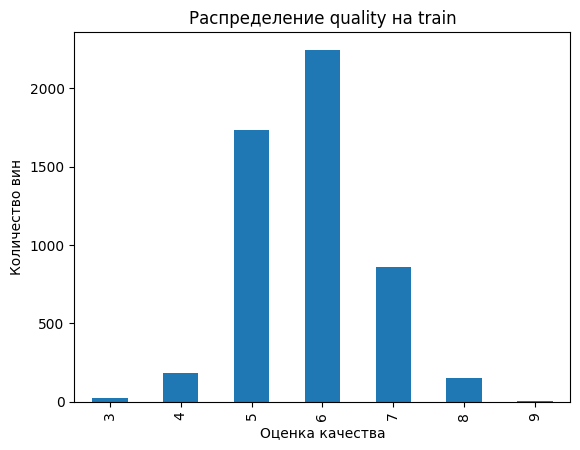

In [4]:

#исследование обучающих данных
train= X_train.copy()
train["quality"] = y_train

counts = train["quality"].value_counts().sort_index()
print(counts)
counts.plot.bar()

plt.xlabel("Оценка качества")
plt.ylabel("Количество вин")
plt.title("Распределение quality на train")
plt.show()

оценки сосредоточенны вокруг 5, 6 и 7;
3, 4 ,8, 9 встречаются редко, модель может полохо их предсказывать

alcohol                 0.449868
citric acid             0.083951
free sulfur dioxide     0.051140
sulphates               0.042034
pH                      0.024895
total sulfur dioxide   -0.043429
residual sugar         -0.045340
fixed acidity          -0.081427
is_red                 -0.124386
chlorides              -0.195769
volatile acidity       -0.262143
density                -0.313451
dtype: float64


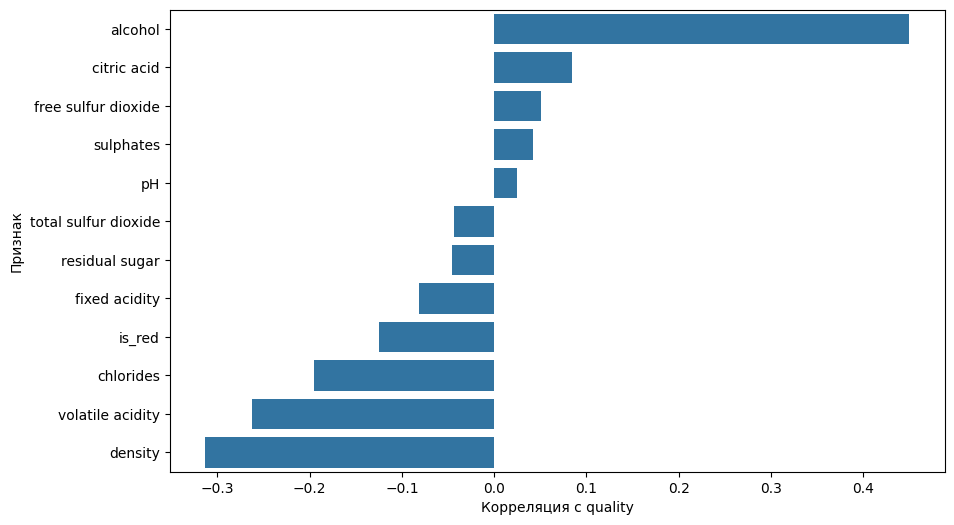

In [5]:
#корреляции

numeric_data = X_train.select_dtypes([np.number])
numeric_features = numeric_data.columns

correlations = X_train[numeric_features].corrwith(y_train).sort_values(ascending=False)

print(correlations)

# Столбчатая диаграмма
plt.figure(figsize=(10, 6))
sns.barplot(x=correlations.values, y=correlations.index)

plt.xlabel("Корреляция с quality")
plt.ylabel("Признак")
plt.show()

ожидаю большие кожэффициенты у линейной модели по модулю у alcohol,chlorides, volatile acidity, density   

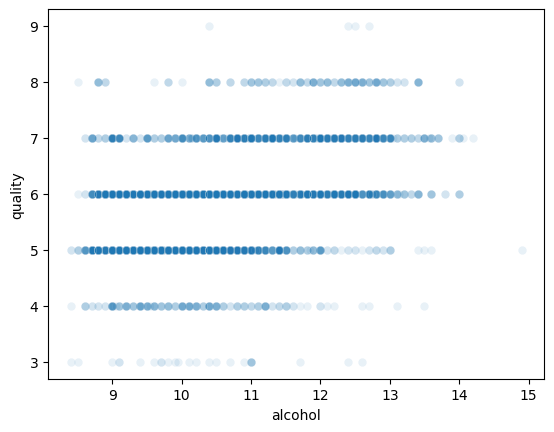

In [6]:
sns.scatterplot(data=train, x="alcohol", y="quality", alpha=0.1)
plt.show()

корреляции

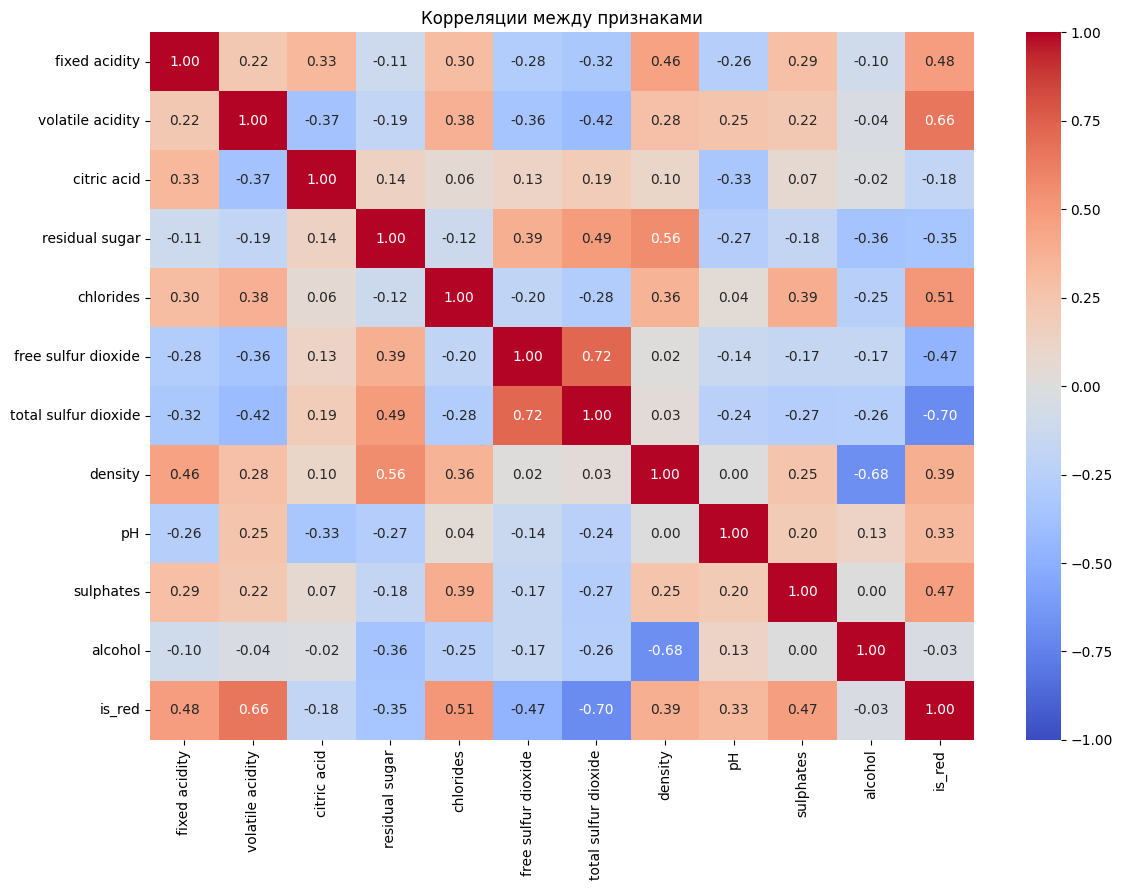

In [7]:
feature_correlations = X_train.corr()

plt.figure(figsize=(12, 9))

sns.heatmap(
    feature_correlations,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    vmin=-1,
    vmax=1,
    center=0
)

plt.title("Корреляции между признаками")
plt.tight_layout()
plt.show()

Между некоторыми признаками есть заметные корреляции: например, свободный и общий диоксид серы — около 0,72.

# 2) BASELINE

In [8]:
#baseline

constant = y_train.mean()
baseline_pred = np.full(len(y_test), constant)


#метрика для baseline

baseline_rmse = root_mean_squared_error(y_test, baseline_pred)
baseline_mae = mean_absolute_error(y_test, baseline_pred)

print('rmse: ',baseline_rmse,'\n','mae: ', baseline_mae)

rmse:  0.8570350102251918 
 mae:  0.6717511582125782


# 3) Линейная регрессия

In [9]:
# линейная регрессия

linear_model = LinearRegression()

linear_model.fit(X_train, y_train)

linear_train_pred = linear_model.predict(X_test)

linear_train_rmse = root_mean_squared_error(y_test, linear_train_pred)
linear_train_mae = mean_absolute_error(y_test, linear_train_pred)

print('rmse: ', linear_train_rmse,'\n','mae: ', linear_train_mae)

rmse:  0.7202626598448714 
 mae:  0.5519106513524595


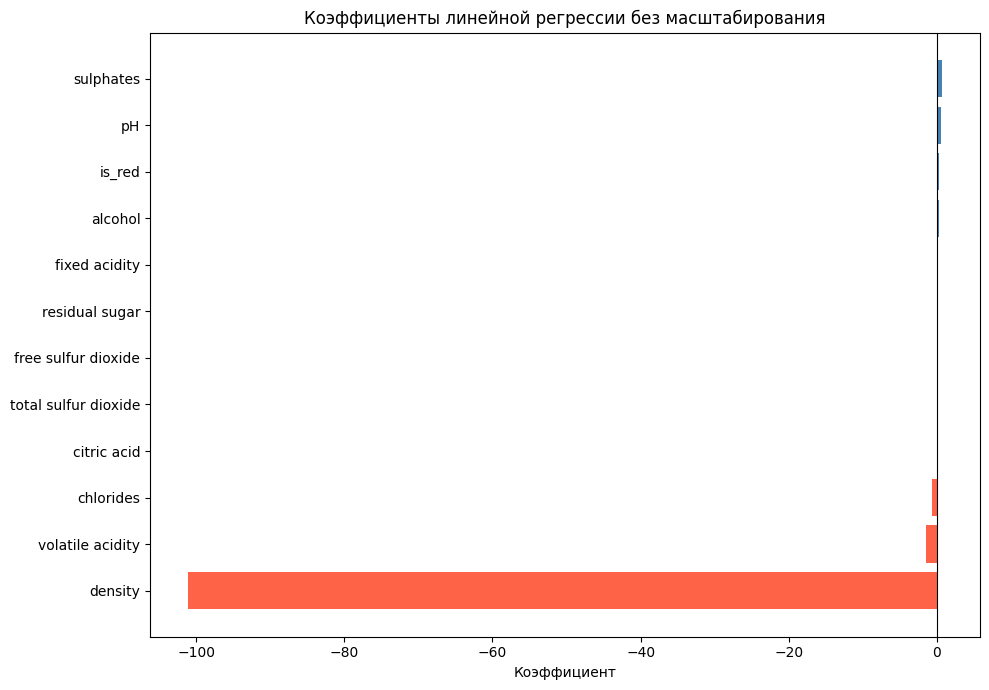

In [10]:
names = X_train.columns

coef = pd.Series(linear_model.coef_.ravel(), index=names)
top_coef = coef.loc[coef.abs().nlargest(30).index].sort_values()

plt.figure(figsize=(10, 7))
plt.barh(
    top_coef.index,
    top_coef.values,
    color=["tomato" if v < 0 else "steelblue" for v in top_coef.values]
)

plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Коэффициент")
plt.title("Коэффициенты линейной регрессии без масштабирования")
plt.tight_layout()
plt.show()

Коэффициенты корректны, но их величины нельзя напрямую сравнивать из-за разных масштабов признаков

In [11]:
feature_std = X_train.std(ddof=0)

linear_coef = pd.DataFrame(
    {
        "Исходный коэффициент": linear_model.coef_,
        "стандартизировали": linear_model.coef_ * feature_std
    },
    index=X_train.columns
)

# Сортируем по модулю, сохраняя знак коэффициента
order = (
    linear_coef["стандартизировали"]
    .abs()
    .sort_values(ascending=False)
    .index
)

linear_coef = linear_coef.loc[order]

display(linear_coef.round(4))
print("Свободный член:", linear_model.intercept_)

,Исходный коэффициент,стандартизировали
density,-101.1150,-0.3043
residual sugar,0.0613,0.2929
alcohol,0.2298,0.2735
volatile acidity,-1.4536,-0.2385
is_red,0.3220,0.1381
fixed acidity,0.0818,0.1067
sulphates,0.7180,0.1055
total sulfur dioxide,-0.0015,-0.0867
free sulfur dioxide,0.0045,0.0804
pH,0.4910,0.0795


Свободный член: 101.58144273236955


Исходные коэффициенты нельзя сравнивать напрямую, поскольку
признаки измеряются в разных единицах и имеют разный разброс.

После учёта масштаба наиболее выраженные коэффициенты наблюдаются
у density (-0.304), residual sugar (+0.293), alcohol (+0.273)
и volatile acidity (-0.239)
Например, увеличение alcohol на одно стандартное отклонение
соответствует увеличению прогноза примерно на 0.273 балла
при неизменных остальных признаках

Большой исходный коэффициент density (около -101) частично
объясняется малым численным разбросом плотности. После учёта
масштаба его величина сопоставима с другими ведущими признаками.

результаты метрики неудовлетворительны, корреляции слабые возможно зависимости нелинейные


задаю правило разделения на фолды

In [12]:
from sklearn.model_selection import KFold, cross_validate

cv = KFold(n_splits=5, shuffle=True, random_state=42)


проверю, получится ли улучшить модель если убрать самые скореллированные признаки

In [13]:
variants = {
    "Все признаки": [],
    "Без is_red": ["is_red"],
    "Без density": ["density"],
    "Без обоих": ["is_red", "density"]
}

rows = []

scoring = {
    "RMSE": "neg_root_mean_squared_error",
    "MAE": "neg_mean_absolute_error",
}

for name, dropped_columns in variants.items():
    scores = cross_validate(
        linear_model,
        X_train.drop(columns=dropped_columns),
        y_train,
        cv=cv,
        scoring=scoring,
        n_jobs=3
    )

    rows.append({
        "Вариант": name,
        "CV_RMSE": -scores["test_RMSE"].mean()
    })

pd.DataFrame(rows).sort_values("CV_RMSE")

,Вариант,CV_RMSE
0,Все признаки,0.738309
1,Без is_red,0.739630
2,Без density,0.740754
3,Без обоих,0.740932


ВЫВОД: Удаление проверенных признаков не улучшило CV, поэтому они сохранены. Этот эксперимент не доказывает нелинейность.

# Полиномизация
поскольку зависимости нелинейны, проведем полиномизацию признаков и подберем степень полиномизации

Квантильное преобразование преобразует распределения отдельных признаков к близким к нормальному;

In [14]:
from sklearn.preprocessing import PolynomialFeatures

poly_pipeline = Pipeline([
    ("quantile", QuantileTransformer(
        output_distribution="normal",
        n_quantiles=500,
        random_state=42)),
    ("poly", PolynomialFeatures(include_bias=False)),
    ("scaler", StandardScaler()),
    ("model", Ridge(tol = 0.01))
])

poly_search = GridSearchCV(
    estimator=poly_pipeline,
    param_grid={
    "poly__degree": [1, 2, 3, 4],
    "model__alpha": [0.00001, 0.0001, 0.001, 0.01, 0.1, 1, 10, 100, 1000, 10000, 100000]},
    scoring="neg_root_mean_squared_error",
    cv=cv,
    return_train_score=True,
    n_jobs=4,
    error_score="raise",  # сразу показать ошибку, если обучение не удалось
    verbose=1            # показывать ход поиска
)

poly_search.fit(X_train, y_train)

print("Лучшая alpha:", poly_search.best_params_["model__alpha"])
print("Лучшая degree:", poly_search.best_params_["poly__degree"])
print("CV RMSE:", -poly_search.best_score_)


best_poly_search = poly_search.best_estimator_
y_pred = best_poly_search.predict(X_test)


Fitting 5 folds for each of 44 candidates, totalling 220 fits
Лучшая alpha: 1000
Лучшая degree: 3
CV RMSE: 0.7040847796178147


In [15]:


print('проверка на тестовых данных\n')
print('RMSE on test', root_mean_squared_error(y_test, y_pred))
print('MAE on test', mean_absolute_error(y_test, y_pred))


проверка на тестовых данных

RMSE on test 0.6738471392997658
MAE on test 0.5200747771526038


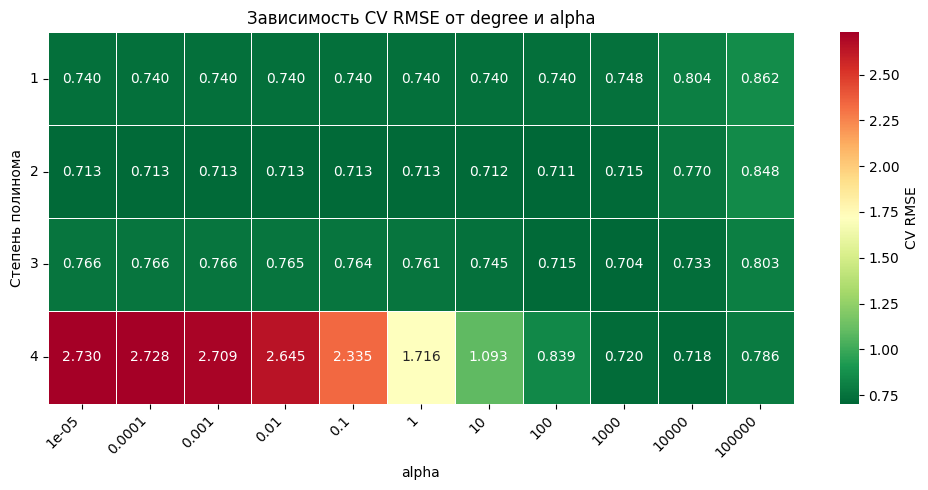

In [16]:
results = pd.DataFrame(poly_search.cv_results_)

results["degree"] = results["param_poly__degree"].astype(int)
results["alpha"] = results["param_model__alpha"].astype(float)

# Меняем знак, поскольку scoring был neg_root_mean_squared_error
results["CV_RMSE"] = -results["mean_test_score"]

rmse_table = (
    results.pivot(index="degree", columns="alpha", values="CV_RMSE")
    .sort_index()
    .sort_index(axis=1)
)

plt.figure(figsize=(max(10, 0.8 * len(rmse_table.columns)), 5))

sns.heatmap(
    rmse_table,
    annot=True,
    fmt=".3f",
    cmap="RdYlGn_r",
    linewidths=0.5,
    xticklabels=[f"{alpha:g}" for alpha in rmse_table.columns],
    cbar_kws={"label": "CV RMSE"}
)

plt.xlabel("alpha")
plt.ylabel("Степень полинома")
plt.title("Зависимость CV RMSE от degree и alpha")
plt.xticks(rotation=45, ha="right")
plt.yticks(rotation=0)
plt.tight_layout()
plt.show()

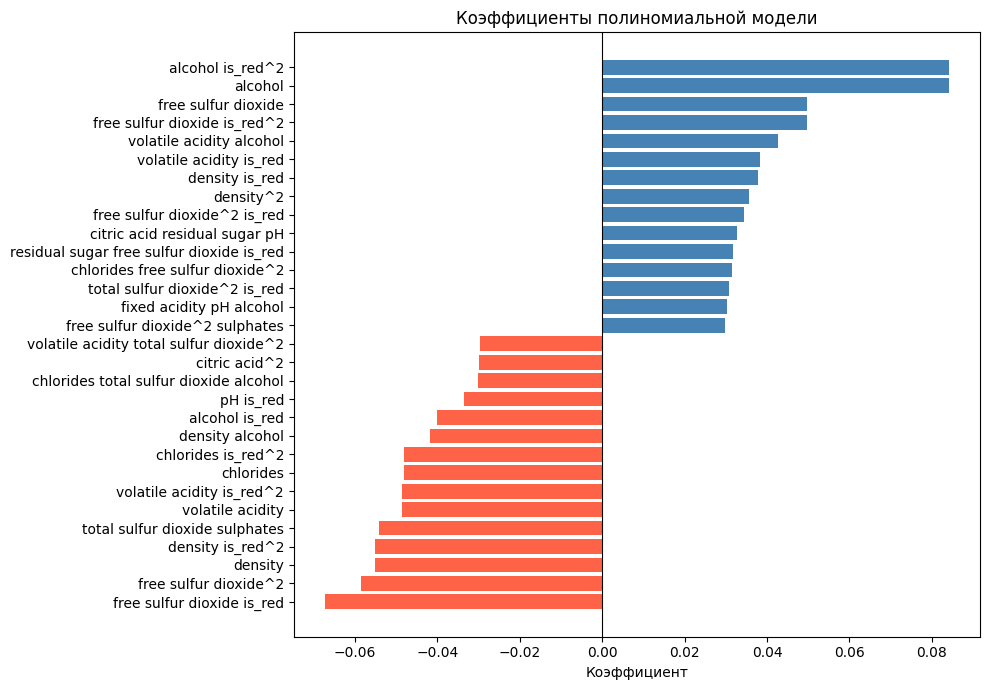

In [17]:
model = best_poly_search.named_steps["model"]
names = best_poly_search.named_steps["poly"].get_feature_names_out(
    X_train.columns
)

coef = pd.Series(model.coef_, index=names)
top_coef = coef.loc[coef.abs().nlargest(30).index].sort_values()

plt.figure(figsize=(10, 7))
plt.barh(
    top_coef.index,
    top_coef.values,
    color=["tomato" if v < 0 else "steelblue" for v in top_coef.values]
)
plt.axvline(0, color="black", linewidth=0.8)
plt.xlabel("Коэффициент")
plt.title("Коэффициенты полиномиальной модели")
plt.tight_layout()
plt.show()

alcohol,chlorides, volatile acidity, density оказались одними из самых значимых признаков, однако большие коэффициенты при квадратах и произведениях признаков указывают на сложную нелинейную зависимость

# Random forest


делаю подбор модели с лучшими показателями rmse 

In [18]:
from sklearn.model_selection import RandomizedSearchCV


forest_search = RandomizedSearchCV(
    estimator=RandomForestRegressor(
    random_state=10,
    n_jobs=1),
    param_distributions={
        "n_estimators": [200, 300, 600],
        "max_depth": [None, 8, 15, 25],
        "min_samples_leaf": [1, 2, 4, 8],
        "max_features": [0.5, 0.75, 1.0],
    },
    n_iter=15,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=8,
    n_jobs=4,
    return_train_score=True,
    error_score="raise",
    verbose=1,
)

forest_search.fit(X_train, y_train)


Fitting 5 folds for each of 15 candidates, totalling 75 fits


,"estimator estimator: estimator objectAn object of that type is instantiated for each grid point.This is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",RandomForestR...ndom_state=10)
,"param_distributions param_distributions: dict or list of dictsDictionary with parameters names (`str`) as keys and distributionsor lists of parameters to try. Distributions must provide a ``rvs``method for sampling (such as those from scipy.stats.distributions).If a list is given, it is sampled uniformly.If a list of dicts is given, first a dict is sampled uniformly, andthen a parameter is sampled using that dict as above.","{'max_depth': [None, 8, ...], 'max_features': [0.5, 0.75, ...], 'min_samples_leaf': [1, 2, ...], 'n_estimators': [200, 300, ...]}"
,"n_iter n_iter: int, default=10Number of parameter settings that are sampled. n_iter tradesoff runtime vs quality of the solution.",15
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.If None, the estimator's score method is used.",'neg_root_mean_squared_error'
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",4
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",KFold(n_split... shuffle=True)
,"verbose verbose: int, default = 0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"random_state random_state: int, RandomState instance or None, default=NonePseudo random number generator state used for random uniform samplingfrom lists of possible values instead of scipy.stats distributions.Pass an int for reproducible output across multiplefunction calls.See :term:`Glossary <random_state>`.",8
,"error_score error_score: 'raise' or numeric, default=np.nanValue to assign to the score if an error occurs in estimator fitting.If set to 'raise', the error is raised. If a numeric value is given,FitFailedWarning is raised. This parameter does not affect the refitstep, which will always raise the error.",'raise'
,"return_train_score return_train_score: bool, def

In [19]:

print("Лучшие параметры:", forest_search.best_params_)
print("CV RMSE:", -forest_search.best_score_)

forest_test_pred = forest_search.best_estimator_.predict(X_test)

print("Random Forest: тест")
print("Test RMSE:", root_mean_squared_error(y_test, forest_test_pred))
print("Test MAE:", mean_absolute_error(y_test, forest_test_pred))

Лучшие параметры: {'n_estimators': 600, 'min_samples_leaf': 1, 'max_features': 0.5, 'max_depth': 25}
CV RMSE: 0.6211313795217892
Random Forest: тест
Test RMSE: 0.5664988016948366
Test MAE: 0.39771497533935146


alcohol                 0.202
volatile acidity        0.115
density                 0.102
free sulfur dioxide     0.090
sulphates               0.076
total sulfur dioxide    0.074
chlorides               0.073
residual sugar          0.070
citric acid             0.068
pH                      0.067
fixed acidity           0.060
is_red                  0.002
dtype: float64

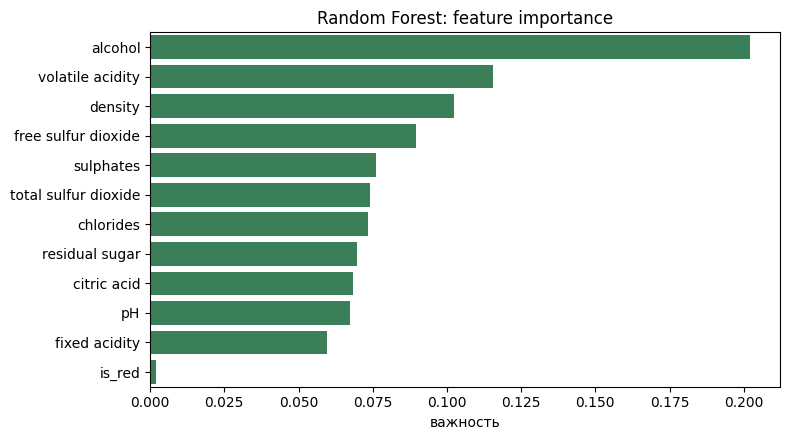

In [20]:
rf_imp = pd.Series(forest_search.best_estimator_.feature_importances_, index=X.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=rf_imp.values, y=rf_imp.index, ax=ax, color="seagreen")
ax.set_title("Random Forest: feature importance"); ax.set_xlabel("важность"); ax.set_ylabel("")
plt.tight_layout()
rf_imp.round(3)

# Gradient Boosting

In [21]:
# Gradient Boosting

boosting_search = RandomizedSearchCV(
    estimator=GradientBoostingRegressor(
    random_state=10),
    param_distributions={
        "n_estimators": [200, 400, 600],
        "learning_rate": [0.02, 0.05, 0.1],
        "max_depth": [2, 3, 4],
        "min_samples_leaf": [1, 5, 10],
        "subsample": [0.7, 1.0],
    },
    n_iter=15,
    scoring="neg_root_mean_squared_error",
    cv=cv,
    random_state=42,
    n_jobs=4,
    return_train_score=True,
    error_score="raise",
    verbose=1,
)

boosting_search.fit(X_train, y_train)

print("Лучшие параметры:", boosting_search.best_params_)
print("CV RMSE:", -boosting_search.best_score_)

boosting_test_pred = boosting_search.best_estimator_.predict(X_test)

print("\nGradient Boosting:")
print("Test RMSE:", root_mean_squared_error(y_test, boosting_test_pred))
print("Test MAE:", mean_absolute_error(y_test, boosting_test_pred))

Fitting 5 folds for each of 15 candidates, totalling 75 fits
Лучшие параметры: {'subsample': 0.7, 'n_estimators': 600, 'min_samples_leaf': 1, 'max_depth': 4, 'learning_rate': 0.05}
CV RMSE: 0.6583557593707531

Gradient Boosting:
Test RMSE: 0.6081140022442719
Test MAE: 0.45728010941801567


alcohol                 0.267
volatile acidity        0.133
free sulfur dioxide     0.092
sulphates               0.076
residual sugar          0.068
total sulfur dioxide    0.068
density                 0.067
citric acid             0.060
pH                      0.058
chlorides               0.057
fixed acidity           0.053
is_red                  0.002
dtype: float64

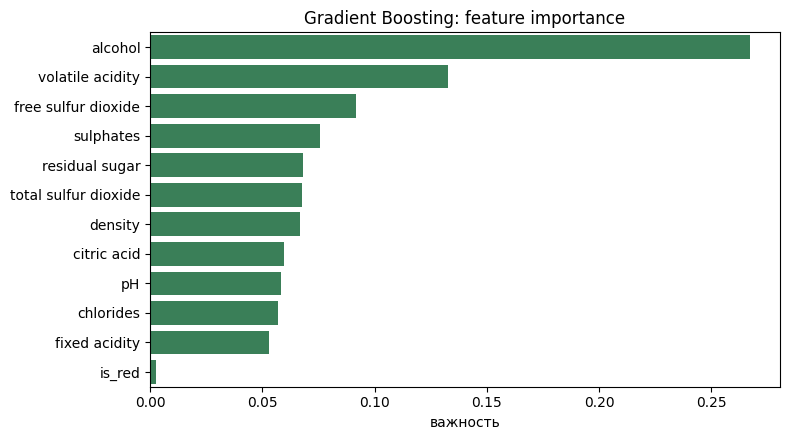

In [22]:
bf_imp = pd.Series(boosting_search.best_estimator_.feature_importances_, index=X.columns).sort_values(ascending=False)
fig, ax = plt.subplots(figsize=(8, 4.5))
sns.barplot(x=bf_imp.values, y=bf_imp.index, ax=ax, color="seagreen")
ax.set_title("Gradient Boosting: feature importance"); ax.set_xlabel("важность"); ax.set_ylabel("")
plt.tight_layout()
bf_imp.round(3)

# Сравнение моделей

модели обучены и проверяются на одних и тех же данных

In [23]:
predictions = {
    "Baseline": np.full(len(y_test), y_train.mean()),
    "Линейная регрессия": linear_model.predict(X_test),
    "Полином + Ridge": poly_search.best_estimator_.predict(X_test),
    "Случайный лес": forest_search.best_estimator_.predict(X_test),
    "Градиентный бустинг": boosting_search.best_estimator_.predict(X_test),
}

comparison_rows = []

for name, pred in predictions.items():
    comparison_rows.append({
        "Модель": name,
        "RMSE": root_mean_squared_error(y_test, pred),
        "MAE": mean_absolute_error(y_test, pred),
    })

comparison = (
    pd.DataFrame(comparison_rows)
    .set_index("Модель")
    .sort_values("RMSE")
)

display(comparison.round(4))

,RMSE,MAE
Модель,,
Случайный лес,0.5665,0.3977
Градиентный бустинг,0.6081,0.4573
Полином + Ridge,0.6738,0.5201
Линейная регрессия,0.7203,0.5519
Baseline,0.8570,0.6718


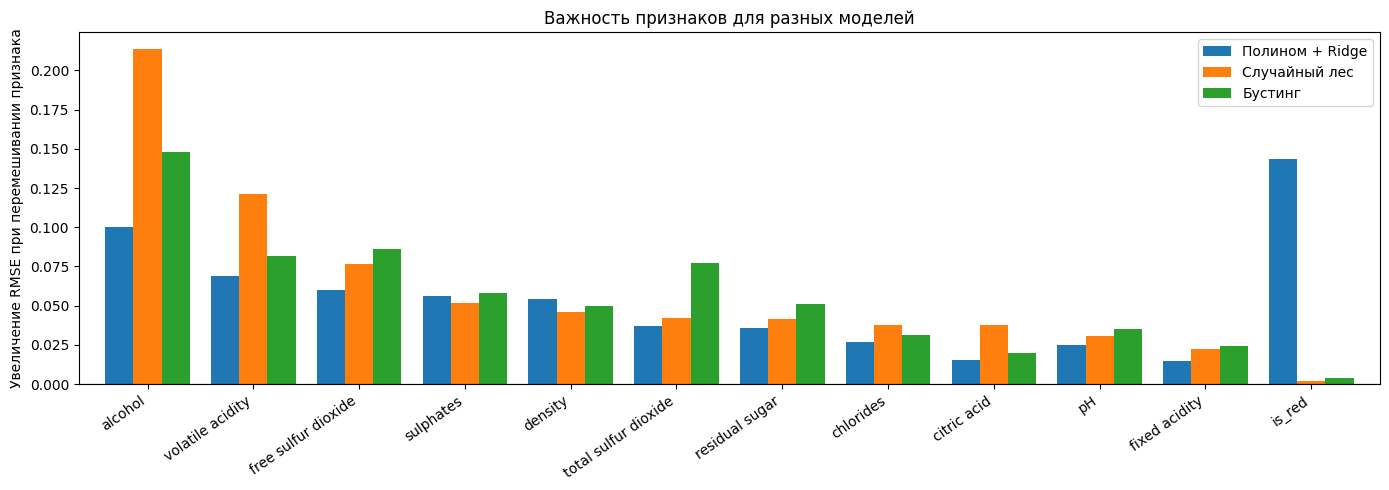

,Полином + Ridge,Случайный лес,Бустинг
#1,is_red,alcohol,alcohol
#2,alcohol,volatile acidity,free sulfur dioxide
#3,volatile acidity,free sulfur dioxide,volatile acidity
#4,free sulfur dioxide,sulphates,total sulfur dioxide
#5,sulphates,density,sulphates


In [24]:
from sklearn.inspection import permutation_importance

models = {
    "Полином + Ridge": poly_search.best_estimator_,
    "Случайный лес": forest_search.best_estimator_,
    "Бустинг": boosting_search.best_estimator_,
}

importance = {}

for name, model in models.items():
    result = permutation_importance(
        model, X_test, y_test,
        scoring="neg_root_mean_squared_error",
        n_repeats=10,
        random_state=42,
        n_jobs=2
    )
    importance[name] = result.importances_mean

imp = pd.DataFrame(importance, index=X_test.columns)
imp = imp.sort_values("Случайный лес", ascending=False)

# Совмещённый график
ax = imp.plot.bar(figsize=(14, 5), width=0.8)
ax.set_ylabel("Увеличение RMSE при перемешивании признака")
ax.set_title("Важность признаков для разных моделей")
ax.axhline(0, color="black", linewidth=0.8)
plt.xticks(rotation=35, ha="right")
plt.tight_layout()
plt.show()

# Топ-5 каждой модели
top5 = pd.DataFrame(
    {name: imp[name].nlargest(5).index for name in imp.columns},
    index=[f"#{i}" for i in range(1, 6)]
)

display(top5)

У случайного леса и бустинга первые три признака совпадают:
alcohol, volatile acidity и free sulfur dioxide.
Значимость алкоголя и летучей кислотности согласуется с EDA.

При этом free sulfur dioxide имеет слабую линейную корреляцию
с качеством, но заметную важность в деревьях. Это может объясняться
нелинейными зависимостями и взаимодействиями с другими признаками.

Линейная регрессия использует простую зависимость: каждый признак
вносит фиксированный вклад в прогноз качества.

Другие модели могут учитывать, что роль одного признака зависит
от остальных характеристик вина. Например, связь алкоголя
с качеством может различаться при разной кислотности.

Вероятно, такие зависимости присутствуют в наших данных.
Поэтому полиномиальная модель, случайный лес и бустинг показали
меньшую ошибку, чем обычная линейная регрессия.

# Анализ ошибок лучшей модели - Случайного леса

лес выбран на основе метрики на cv данных

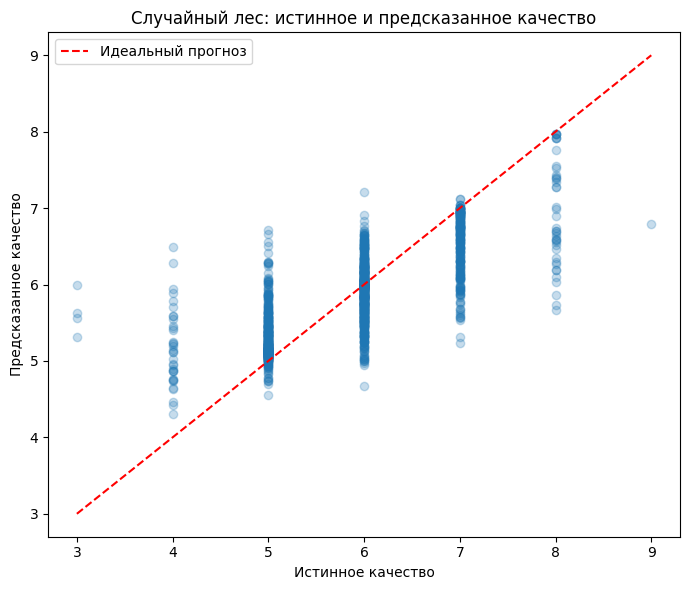

In [25]:
best_pred = forest_search.best_estimator_.predict(X_test)

plt.figure(figsize=(7, 6))

plt.scatter(y_test, best_pred, alpha=0.25)

limits = [
    min(y_test.min(), best_pred.min()),
    max(y_test.max(), best_pred.max())
]
plt.plot(limits, limits, "r--", label="Идеальный прогноз")

plt.xlabel("Истинное качество")
plt.ylabel("Предсказанное качество")
plt.title("Случайный лес: истинное и предсказанное качество")
plt.legend()
plt.tight_layout()
plt.show()

In [26]:
errors = X_test.copy()
errors["Факт"] = y_test
errors["Прогноз"] = forest_search.best_estimator_.predict(X_test)
errors["Ошибка"] = errors["Прогноз"] - errors["Факт"]
errors["Абсолютная ошибка"] = errors["Ошибка"].abs()

# Ошибки отдельно для каждого истинного значения quality
errors_by_quality = errors.groupby("Факт").agg(
    Количество=("Ошибка", "size"),
    RMSE=("Ошибка", lambda e: np.sqrt((e ** 2).mean())),
    MAE=("Абсолютная ошибка", "mean"),
    Средняя_ошибка=("Ошибка", "mean")
)

display(errors_by_quality.round(3))

# Пять худших прогнозов
worst = errors.nlargest(5, "Абсолютная ошибка")

display(
    worst[
        [
            "Факт", "Прогноз", "Ошибка",
            "alcohol", "volatile acidity",
            "density", "free sulfur dioxide", "is_red"
        ]
    ].round(3)
)

,Количество,RMSE,MAE,Средняя_ошибка
Факт,,,,
3,4,2.638,2.626,2.626
4,35,1.284,1.180,1.180
5,405,0.468,0.348,0.332
6,592,0.378,0.290,-0.090
7,222,0.629,0.480,-0.477
8,41,1.266,1.066,-1.066
9,1,2.206,2.206,-2.206


,Факт,Прогноз,Ошибка,alcohol,volatile acidity,density,free sulfur dioxide,is_red
2044,3,5.999,2.999,11.5,0.320,0.994,16.0,0
5409,3,5.633,2.633,10.5,0.260,0.997,42.0,0
4864,3,5.560,2.560,8.0,0.215,0.997,64.0,0
5016,4,6.485,2.485,12.9,0.640,0.989,18.0,0
5683,8,5.672,-2.328,11.5,0.330,0.995,20.0,0


Лучше всего модель предсказывает качество 6: MAE ≈ 0.290.
Для оценок 5 и 7 MAE составляет около 0.348 и 0.480.
Для оценок 4 и 8 ошибки заметно выше: 1.180 и 1.066 соответственно.

Модель преимущественно завышает низкие оценки и занижает высокие.
Например, объекту 2044 с оценкой 3 предсказано около 6,
а объекту 5683 с оценкой 8 — около 5.67.

Это согласуется с гипотезой из EDA: редкие крайние оценки
предсказываются хуже. Возможные причины — недостаток таких
примеров в обучении и усреднение прогнозов деревьев.

Для quality=3 в тесте всего четыре объекта, а для quality=9 —
один, поэтому оценки ошибок этих групп особенно неустойчивы.

## распределение ошибок

In [27]:
display(
    errors["Ошибка"]
    .describe(percentiles=[0.05, 0.25, 0.5, 0.75, 0.95])
    .to_frame("Прогноз − факт")
    .round(3)
)

,Прогноз − факт
count,1300.000
mean,-0.015
std,0.567
min,-2.328
5%,-0.953
25%,-0.286
50%,0.007
75%,0.251
95%,0.855
max,2.999


## Доля хороших прогнозов

In [28]:
share = (errors["Абсолютная ошибка"] < 0.5).mean()

print(f"Доля прогнозов с ошибкой не более 0.5 балла: {share:.1%}")

Доля прогнозов с ошибкой не более 0.5 балла: 71.5%


На тестовой выборке 71,5% прогнозов отличаются от истинной оценки менее чем на 0,5 балла.

# Вывод

Все обученные модели превзошли baseline, который предсказывал
среднее качество вина. Лучший результат показал случайный лес:
RMSE = 0.5665 и MAE = 0.3977. Таким образом, его средняя абсолютная
ошибка на тестовой выборке составляет около 0.40 балла качества.

Полиномиальный пайплайн и ансамбли оказались точнее обычной
линейной регрессии. Возможное объяснение — способность учитывать
нелинейные зависимости и взаимодействия характеристик вина.
При выбранных настройках случайный лес показал лучший результат
среди рассмотренных моделей.

По встроенным оценкам важности случайного леса и бустинга
наиболее значимыми признаками стали alcohol, volatile acidity
и free sulfur dioxide. Результаты частично согласуются с EDA,
но показывают, что слабая отдельная линейная корреляция
не обязательно означает низкую полезность признака для модели.

Важность признаков не доказывает причинного влияния на качество.
Она показывает, как модель использует наблюдаемые зависимости.
Например, высокая важность alcohol не означает, что добавление
алкоголя в конкретное вино обязательно повысит его качество:
содержание алкоголя связано и с другими характеристиками вина.

На локальной тестовой выборке достигнут RMSE ниже 0.70.
Для подтверждения выполнения требования задания необходима
оценка на скрытой тестовой выборке.